In [1]:
import sys
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "1"

print(sys.executable)
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))

/mnt/milan/mamba-midterm/.venv/bin/python
CUDA_VISIBLE_DEVICES: 1


In [2]:
import torch

print("Visible GPUs:", torch.cuda.device_count())
print("GPU Name:", torch.cuda.get_device_name(0))

Visible GPUs: 1
GPU Name: NVIDIA RTX A6000


# Mamba: Selective State Space Models for Text Classification

Mamba is a deep learning architecture that processes sequential data efficiently. It uses Selective State Space Models (SSM) to process sequences while maintaining internal state. 

The main idea behind Mamba is selective memory. The model learns how to update internal state based on current input, allowing it to carry useful information across a sequence.

In this notebook, I use the Mamba implementation from the state-spaces/mamba Github repository to demonstrate how the architecture works. I also train a small Mamba-based model from scratch using the AG News dataset, basically idea is to classify news articles into four categories: World, Sports, Business, and Sci/Tech.

This notebook covers:

1. Loading and preparing the AG News dataset.
2. Build text classification model using mamba.
3. Training and evaluating the model.
4. Testing the trained model on news headlines.
5. Observe Mamba's internal components: linear projection, Conv1D, selective scan, and delta.
6. Visualizing delta values and hidden states to understand how information is processed.


## References
- Github Repo: https://github.com/state-spaces/mamba
- Mamba Architecture Explanation: https://www.youtube.com/watch?v=BDTVVlUU1Ck&t=1141s

In [3]:
import random
import numpy as np
import torch
import transformers
import datasets
import mamba_ssm

print("torch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("mamba_ssm:", mamba_ssm.__version__)
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("GPU:", torch.cuda.get_device_name(0))

# fix seed so results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda"

/mnt/milan/mamba-midterm/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch: 2.6.0+cu124 | CUDA: 12.4
mamba_ssm: 2.2.4
transformers: 4.44.2
datasets: 3.6.0
GPU: NVIDIA RTX A6000


# Data preparation

AG News has **120,000 training** and **7,600 test** articles. The notebook splits training into **108,000 train/12,000** validation articles.

In [4]:
from datasets import load_dataset

raw = load_dataset("fancyzhx/ag_news")
print(raw)

split = raw["train"].train_test_split(test_size=0.1, seed=SEED)
train_data = split["train"]
val_data = split["test"]
test_data = raw["test"]

label_names = raw["train"].features["label"].names
print(label_names)
print(len(train_data))
print(len(val_data))
print(len(test_data))
print(train_data[0])

Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 1317709.50 examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
['World', 'Sports', 'Business', 'Sci/Tech']
108000
12000
7600
{'text': 'Despair and Anger in Small Russian Town After Siege  BESLAN, Russia (Reuters) - The killing of more than 320  children, parents and teachers during the bloody end to a  53-hour school siege left barely a family untouched in the  small Russian town of Beslan.', 'label': 0}


# Tokenization

BERT WordPiece tokenization may split a word into multiple tokes. Only tokenizer is reused, **no pretrained BERT model weights** are used.

In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
print(tokenizer.vocab_size)

example = train_data[0]["text"]
print(tokenizer.tokenize(example)[:20])
print(tokenizer(example)["input_ids"][:20])

lengths = [len(x) for x in tokenizer(train_data["text"][:5000])["input_ids"]]
print(max(lengths))
print(sum(lengths) / len(lengths))

/mnt/milan/mamba-midterm/.venv/lib/python3.10/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


30522
['despair', 'and', 'anger', 'in', 'small', 'russian', 'town', 'after', 'siege', 'be', '##sl', '##an', ',', 'russia', '(', 'reuters', ')', '-', 'the', 'killing']
[101, 13905, 1998, 4963, 1999, 2235, 2845, 2237, 2044, 6859, 2022, 14540, 2319, 1010, 3607, 1006, 26665, 1007, 1011, 1996]
361
53.2692


# Tokenize and truncate to 128 tokens

In [6]:
MAX_LEN = 128

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_tok = train_data.map(tokenize, batched=True, remove_columns=["text"])
val_tok = val_data.map(tokenize, batched=True, remove_columns=["text"])
test_tok = test_data.map(tokenize, batched=True, remove_columns=["text"])

lengths = [len(x) for x in train_tok["input_ids"]]
print(train_tok)
print(sum(l == MAX_LEN for l in lengths))

Map: 100%|██████████| 7600/7600 [00:00<00:00, 28748.71 examples/s]


Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 108000
})
861


#### **861 of 108,000** training examples reach the 128-token limit after tokenization. these may be truncated.

In [7]:
# collate is added because text has different lengths and needs padding
BATCH_SIZE = 64

def collate(batch):
    ids = [torch.tensor(x["input_ids"]) for x in batch]
    lengths = torch.tensor([len(x) for x in ids])
    ids = torch.nn.utils.rnn.pad_sequence(ids, batch_first=True, padding_value=tokenizer.pad_token_id)
    labels = torch.tensor([x["label"] for x in batch])
    return ids, lengths, labels

trainloader = torch.utils.data.DataLoader(train_tok, batch_size=BATCH_SIZE,
                                          shuffle=True, collate_fn=collate)
valloader = torch.utils.data.DataLoader(val_tok, batch_size=BATCH_SIZE,
                                        shuffle=False, collate_fn=collate)
testloader = torch.utils.data.DataLoader(test_tok, batch_size=BATCH_SIZE,
                                         shuffle=False, collate_fn=collate)

ids, lengths, labels = next(iter(trainloader))
print(ids.shape)
print(lengths[:8])
print(labels[:8])
print(ids[0])

torch.Size([64, 101])
tensor([69, 52, 46, 61, 44, 56, 47, 43])
tensor([1, 2, 3, 2, 1, 3, 2, 3])
tensor([  101,  2417,  9175,  1010, 11081, 20687, 10685,  2012,  3346,  1006,
         9706,  1007,  9706,  1011,  1996,  2197,  2051,  1996,  3731,  2417,
         9175,  4716, 17652,  3346,  1010,  7256,  6892,  2121,  2001,  3480,
         2989,  2132,  8873, 12096,  2046,  1996,  4832,  1010,  2053,  7849,
         7439, 19362,  2527,  2001, 21396,  6834,  1999,  1996,  8655,  5833,
         1998,  2047,  2259,  2001,  4815,  2185,  1999,  1996,  2632,  2264,
         1012,  1037,  2843,  2038,  2904,  2144,  2059,  1012,   102,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0])


#### Input batches are padded to the longest sequence in that batch, so the sequence dimension can be below 128 (saved example is 64 x 101)

# Mamba classifier

Token IDs -> 128-dimensional embeddings -> 2 Mamba blocks -> last real token -> 4 classification scores.

Model has **4,141,060 parameteres.** Its output projection maps internal Mamba features back to 128 dimensions.

In [8]:
# from mamba_ssm/models/mixer_seq_simple.py (state-spaces/mamba v2.2.4)
import torch.nn as nn
from mamba_ssm.models.mixer_seq_simple import MixerModel

# parameters
VOCAB_SIZE = tokenizer.vocab_size
D_MODEL = 128
N_LAYERS = 2
N_OUTPUTS = 4

class TextMamba(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_outputs):
        super(TextMamba, self).__init__()

        self.backbone = MixerModel(d_model=d_model, n_layer=n_layers, d_intermediate=0,
                                   vocab_size=vocab_size,
                                   ssm_cfg={"layer": "Mamba1", "use_fast_path": False},
                                   rms_norm=False, fused_add_norm=False)

        self.FC = nn.Linear(d_model, n_outputs)

    def forward(self, X, lengths):
        # out => batch_size X seq_len X d_model (output for every token)
        out = self.backbone(X)
        # keep only the output at the last real token of each text
        last = out[torch.arange(X.size(0), device=X.device), lengths - 1]
        return self.FC(last)  # batch_size X n_outputs

model = TextMamba(VOCAB_SIZE, D_MODEL, N_LAYERS, N_OUTPUTS).to(device)
print(model)
print(sum(p.numel() for p in model.parameters()))

TextMamba(
  (backbone): MixerModel(
    (embedding): Embedding(30522, 128)
    (layers): ModuleList(
      (0-1): 2 x Block(
        (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (mixer): Mamba(
          (in_proj): Linear(in_features=128, out_features=512, bias=False)
          (conv1d): Conv1d(256, 256, kernel_size=(4,), stride=(1,), padding=(3,), groups=256)
          (act): SiLU()
          (x_proj): Linear(in_features=256, out_features=40, bias=False)
          (dt_proj): Linear(in_features=8, out_features=256, bias=True)
          (out_proj): Linear(in_features=256, out_features=128, bias=False)
        )
      )
    )
    (norm_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  )
  (FC): Linear(in_features=128, out_features=4, bias=True)
)
4141060


In [9]:
dataiter = iter(trainloader)
ids, lengths, labels = next(dataiter)
logits = model(ids.to(device), lengths.to(device))
print(logits.shape)
print(logits[0:10])

torch.Size([64, 4])
tensor([[ 1.1134,  0.3205,  0.7235,  0.6451],
        [ 0.7839,  0.3842,  0.8662,  1.0949],
        [ 0.3627,  0.0689,  0.3544,  0.9016],
        [ 1.0120,  0.4243,  0.6692,  0.4586],
        [ 1.0190, -0.3416,  0.8436,  0.9620],
        [ 0.4109,  0.0381,  0.4267,  0.5373],
        [ 0.7466,  0.4772,  0.5505,  0.6901],
        [ 0.8601,  0.4318,  0.5721,  0.3327],
        [ 1.0296,  0.3408,  0.6604,  0.7903],
        [ 0.0331,  0.4049,  0.4082,  0.1452]], device='cuda:0',
       grad_fn=<SliceBackward0>)


#### Classifier produces **4 logits per article**, giving output shape **(64,4)** for the sampled batch.

# Training

In [10]:
import torch.optim as optim

N_EPOCHS = 5
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def get_accuracy(logit, target, batch_size):
    ''' Obtain accuracy for training round '''
    corrects = (torch.max(logit, 1)[1].view(target.size()).data == target.data).sum()
    accuracy = 100.0 * corrects/batch_size
    return accuracy.item()

# save untrained weights for the before/after comparison later
# (saving follows Week 3, Ch05_PyTorch_class: torch.save(classifier.state_dict(), ...))
torch.save(model.state_dict(), "mamba_untrained.pt")

In [11]:
# follows the training loop in the course RNN notebook (Week 6, RNN_PT_mod.ipynb, cells 48 and 50)
import time

train_loss_list = []
train_acc_list = []
val_loss_list = []
val_acc_list = []

for epoch in range(N_EPOCHS):
    start = time.time()
    train_running_loss = 0.0
    train_acc = 0.0
    model.train()

    # Training loop
    for i, data in enumerate(trainloader):
        optimizer.zero_grad()

        ids, lengths, labels = data
        ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)

        # forward + backward + optimize
        outputs = model(ids, lengths)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_running_loss += loss.detach().item()
        train_acc += get_accuracy(outputs, labels, labels.size(0))

    # Validation loop
    model.eval()
    val_running_loss = 0.0
    val_acc = 0.0
    with torch.no_grad():
        for j, data in enumerate(valloader):
            ids, lengths, labels = data
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)

            outputs = model(ids, lengths)

            val_running_loss += criterion(outputs, labels).item()
            val_acc += get_accuracy(outputs, labels, labels.size(0))

    train_loss_list.append(train_running_loss / (i + 1))
    train_acc_list.append(train_acc / (i + 1))
    val_loss_list.append(val_running_loss / (j + 1))
    val_acc_list.append(val_acc / (j + 1))

    print("Epoch", epoch)
    print("Train loss:", train_loss_list[-1])
    print("Train acc:", train_acc_list[-1])
    print("Val loss:", val_loss_list[-1])
    print("Val acc:", val_acc_list[-1])
    print("Time:", time.time() - start)

Epoch 0
Train loss: 0.31794292582375533
Train acc: 88.28310130331754
Val loss: 0.23136863372031044
Val acc: 92.34541223404256
Time: 10.07771635055542
Epoch 1
Train loss: 0.15360178020826906
Train acc: 94.60993039099526
Val loss: 0.24334291602544328
Val acc: 92.17918882978724
Time: 9.891525983810425
Epoch 2
Train loss: 0.09850926171261067
Train acc: 96.50381368483413
Val loss: 0.2733323292489699
Val acc: 91.97972074468085
Time: 9.86332392692566
Epoch 3
Train loss: 0.06556639674956076
Train acc: 97.66087825829383
Val loss: 0.3284421630718924
Val acc: 91.58909574468085
Time: 9.884577751159668
Epoch 4
Train loss: 0.04703715997852906
Train acc: 98.29217268957346
Val loss: 0.3840982677078152
Val acc: 91.38131648936171
Time: 9.905042171478271


## Training obervations

Validation accuracy is highest at **epoch 1(92.35%),** while training accuracy continues to improve through epoch 5 **(98.29%).** Validation loss also rises after epoch 1, this suggests **overfitting.**

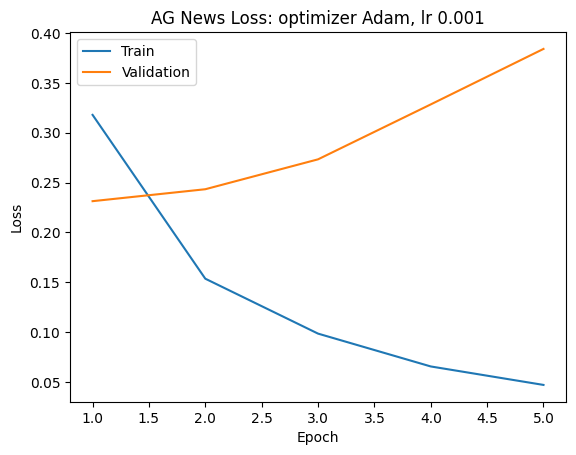

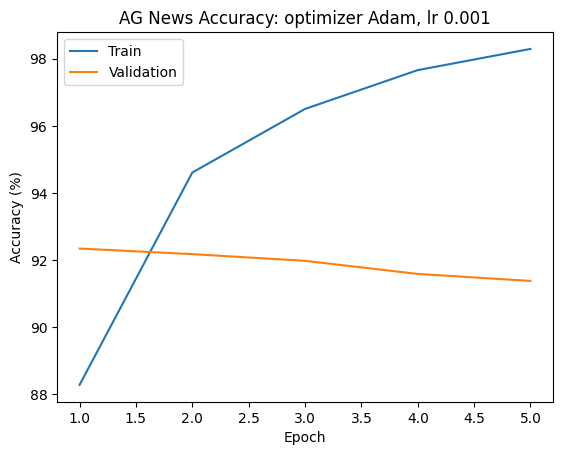

In [13]:
import matplotlib.pyplot as plt

epochs = [i for i in range(1, N_EPOCHS + 1)]

plt.plot(epochs, train_loss_list, label="Train")
plt.plot(epochs, val_loss_list, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AG News Loss: optimizer Adam, lr 0.001")
plt.legend()
plt.show()

plt.plot(epochs, train_acc_list, label="Train")
plt.plot(epochs, val_acc_list, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("AG News Accuracy: optimizer Adam, lr 0.001")
plt.legend()
plt.show()

# Test evaluation

In [14]:
# model.eval() and torch.no_grad() as in the L6 slides ("Train, validate, test")
model.eval()
test_acc = 0.0
with torch.no_grad():
    for i, data in enumerate(testloader):
        ids, lengths, labels = data
        ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)

        outputs = model(ids, lengths)

        test_acc += get_accuracy(outputs, labels, labels.size(0))

print(test_acc / (i + 1))

91.1677171082056


Final model test accuracy is **91.17%**. This evaluates the epoch 5 weights, not the best validation checkpoint. The existing funciton averages per batch accuracies, so the reported values is batch mean approx.

In [15]:
ids, lengths, labels = next(iter(testloader))
with torch.no_grad():
    outputs = model(ids.to(device), lengths.to(device))
_, predicted = torch.max(outputs, 1)

for k in range(8):
    print(test_data[k]["text"][:100])
    print(label_names[labels[k]])
    print(label_names[predicted[k]])
    print()

Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disap
Business
Business

The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - T
Sci/Tech
Sci/Tech

Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at th
Sci/Tech
Sci/Tech

Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his
Sci/Tech
World

Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went aft
Sci/Tech
Sci/Tech

Open Letter Against British Copyright Indoctrination in Schools The British Department for Education
Sci/Tech
Sci/Tech

Loosing the War on Terrorism \\"Sven Jaschan, self-confessed author of the Netsky and Sasser viruses
Sci/Tech
Sci/Tech

FOAFKey: FOAF, PGP, Key Distribution, and Bloom Filters \\FOAF/LOAF  and bloom filters have a lot of
Sci/Tech
Sci/Tech



#### Saved examples show **7 of 8 predictions correct.** The wildfire article is labeled Sci/Tech but predicted as World. These examples are just illustration not full test result.

In [16]:
torch.save(model.state_dict(), "mamba_trained.pt")

# Inside the first Mamba block

Now following cells inspect **layer 1** of the trained model using a single test article. They reconstruct its operations rather than defining a new mamba architecture.
- A: State transition
- B: How input enters the state
- C: How the state produce output
- Δ (delta): Input-dependent step size controlling the state update

In [17]:
# embedding -> norm before the first mixer: from mamba_ssm/models/mixer_seq_simple.py and mamba_ssm/modules/block.py (state-spaces/mamba v2.2.4)
model.load_state_dict(torch.load("mamba_trained.pt"))
model.eval()

text = test_data[1]["text"]
ids = torch.tensor([tokenizer(text, truncation=True, max_length=MAX_LEN)["input_ids"]]).to(device)
tokens = tokenizer.convert_ids_to_tokens(ids[0])

block = model.backbone.layers[0]
mixer = block.mixer

with torch.no_grad():
    hidden = block.norm(model.backbone.embedding(ids))

print(text)
print(tokens)
print(ids.shape)
print(hidden.shape)

The Race is On: Second Private Team Sets Launch Date for Human Spaceflight (SPACE.com) SPACE.com - TORONTO, Canada -- A second\team of rocketeers competing for the  #36;10 million Ansari X Prize, a contest for\privately funded suborbital space flight, has officially announced the first\launch date for its manned rocket.
['[CLS]', 'the', 'race', 'is', 'on', ':', 'second', 'private', 'team', 'sets', 'launch', 'date', 'for', 'human', 'space', '##flight', '(', 'space', '.', 'com', ')', 'space', '.', 'com', '-', 'toronto', ',', 'canada', '-', '-', 'a', 'second', '\\', 'team', 'of', 'rocket', '##eers', 'competing', 'for', 'the', '#', '36', ';', '10', 'million', 'an', '##sari', 'x', 'prize', ',', 'a', 'contest', 'for', '\\', 'privately', 'funded', 'sub', '##or', '##bit', '##al', 'space', 'flight', ',', 'has', 'officially', 'announced', 'the', 'first', '\\', 'launch', 'date', 'for', 'its', 'manned', 'rocket', '.', '[SEP]']
torch.Size([1, 77])
torch.Size([1, 77, 128])


# Input projection and local convolution

In [18]:
# from mamba_ssm/modules/mamba_simple.py, Mamba.forward (state-spaces/mamba v2.2.4)
from einops import rearrange

with torch.no_grad():
    batch, seqlen, dim = hidden.shape
    xz = rearrange(
        mixer.in_proj.weight @ rearrange(hidden, "b l d -> d (b l)"),
        "d (b l) -> b d l",
        l=seqlen,
    )
    x, z = xz.chunk(2, dim=1)
    x_conv = mixer.act(mixer.conv1d(x)[..., :seqlen])

print(xz.shape)
print(x.shape)
print(z.shape)
print(x_conv.shape)

torch.Size([1, 512, 77])
torch.Size([1, 256, 77])
torch.Size([1, 256, 77])
torch.Size([1, 256, 77])


#### Projection produces **512 features**, split into **256 main path** and **256 gate path** features. Convolution keeps the **77 token** sequence length.

# Selective SSM parameters

In [19]:
# from mamba_ssm/modules/mamba_simple.py, Mamba.forward (state-spaces/mamba v2.2.4)
import torch.nn.functional as F

with torch.no_grad():
    x_dbl = mixer.x_proj(rearrange(x_conv, "b d l -> (b l) d"))
    dt, B, C = torch.split(x_dbl, [mixer.dt_rank, mixer.d_state, mixer.d_state], dim=-1)
    dt = mixer.dt_proj.weight @ dt.t()
    dt = rearrange(dt, "d (b l) -> b d l", l=seqlen)
    B = rearrange(B, "(b l) dstate -> b dstate l", l=seqlen).contiguous()
    C = rearrange(C, "(b l) dstate -> b dstate l", l=seqlen).contiguous()
    A = -torch.exp(mixer.A_log.float())

    # from mamba_ssm/ops/selective_scan_interface.py, selective_scan_ref:
    # delta = delta + delta_bias, then softplus
    delta = F.softplus(dt + mixer.dt_proj.bias[..., None])

print(dt.shape)
print(B.shape)
print(C.shape)
print(A.shape)
print(delta.shape)
print(delta.min().item())
print(delta.max().item())

torch.Size([1, 256, 77])
torch.Size([1, 16, 77])
torch.Size([1, 16, 77])
torch.Size([256, 16])
torch.Size([1, 256, 77])
8.002029062481597e-05
1.967025637626648


#### **A** has shape **(256,16)**, **B** and **C** each have **16 state values per token**, and delta has **256 channel values per token.** For this article, delta ranges from **0.000080 to 1.9670**.

# Selective scan and output verification

In [20]:
# from mamba_ssm/modules/mamba_simple.py, Mamba.forward (state-spaces/mamba v2.2.4)
from mamba_ssm.ops.selective_scan_interface import selective_scan_fn

with torch.no_grad():
    y = selective_scan_fn(
        x_conv,
        dt,
        A,
        B,
        C,
        mixer.D.float(),
        z=z,
        delta_bias=mixer.dt_proj.bias.float(),
        delta_softplus=True,
        return_last_state=False,
    )
    y = rearrange(y, "b d l -> b l d")
    out = mixer.out_proj(y)

    real_out = mixer(hidden)

print(out.shape)
print((out - real_out).abs().max().item())

torch.Size([1, 77, 128])
0.0


#### Reconstructed block output and mixer(hidden) match exactly for this tested input, maximum absolute diff is 0.0.

## Delta across token positions

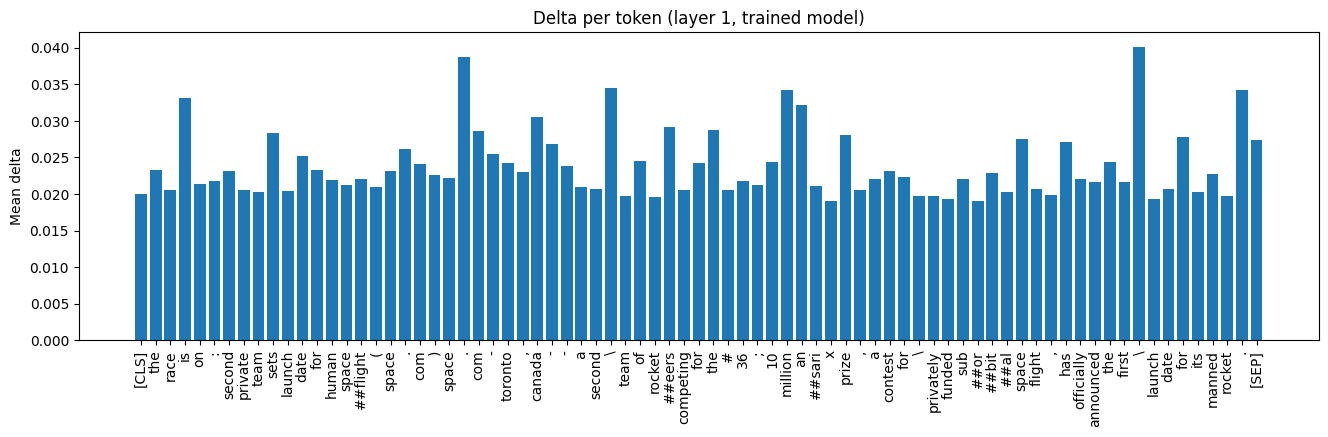

['\\', '.', '\\', 'million', '.', 'is', 'an', 'canada', '##eers', 'the']
tensor([0.0401, 0.0387, 0.0345, 0.0343, 0.0343, 0.0331, 0.0321, 0.0305, 0.0292,
        0.0287])


In [21]:
delta_per_token = delta[0].mean(dim=0).cpu()

plt.figure(figsize=(16, 4))
plt.bar(range(seqlen), delta_per_token)
plt.xticks(range(seqlen), tokens, rotation=90)
plt.ylabel("Mean delta")
plt.title("Delta per token (layer 1, trained model)")
plt.show()

top = torch.argsort(delta_per_token, descending=True)[:10]
print([tokens[k] for k in top])
print(delta_per_token[top])

### Delta values change for different token positions, here highest average value is around **0.0401**. This shows that Mamba adjusts how quickly it updates its memory depending on the input. Higher delta means model can reduce the influence of previous memory more strongly.

In [22]:
top = torch.argsort(delta[0].flatten(), descending=True)[:10]
channels = top // seqlen
positions = top % seqlen

print(channels.tolist())
print([tokens[t] for t in positions])
print(delta[0].flatten()[top])

[242, 242, 242, 242, 54, 242, 76, 102, 242, 242]
['.', '.', 'prize', 'an', 'com', 'sets', '\\', '.', 'million', '.']
tensor([1.9670, 1.3888, 1.1447, 0.9492, 0.9207, 0.8907, 0.8764, 0.8607, 0.8383,
        0.8274], device='cuda:0')


# Hidden state evolution

In [23]:
# from mamba_ssm/ops/selective_scan_interface.py, selective_scan_ref (state-spaces/mamba v2.2.4)
from mamba_ssm.ops.selective_scan_interface import selective_scan_ref

h_list = []
with torch.no_grad():
    for t in range(1, seqlen + 1):
        _, h_t = selective_scan_ref(
            x_conv[..., :t], dt[..., :t], A, B[..., :t], C[..., :t], mixer.D.float(),
            z=z[..., :t], delta_bias=mixer.dt_proj.bias.float(), delta_softplus=True,
            return_last_state=True,
        )
        h_list.append(h_t[0])

    h_all = torch.stack(h_list)

    y_ref = selective_scan_ref(
        x_conv, dt, A, B, C, mixer.D.float(),
        z=z, delta_bias=mixer.dt_proj.bias.float(), delta_softplus=True,
    )

print(h_all.shape)
print((rearrange(y_ref, "b d l -> b l d") - y).abs().max().item())

torch.Size([77, 256, 16])
0.0003662109375


Using Mamba's reference selective scan, we captured how the hidden state changes across 77 tokens. We compared its output with the optimized selective scan and found a maximum difference of only **0.000366**, showing that both implementations produce nearly same results.